<a href="https://colab.research.google.com/github/navyashreenavy/PADV/blob/main/4_Step_Classification_Pipeline_Breast_Cancer_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4-Step Classification Pipeline

## Breast Cancer Wisconsin Diagnostic Dataset + SVM

This notebook implements the four steps shown in the project diagram:
1. **Data Preparation**
2. **Feature Selection**
3. **Model Training**
4. **Evaluation**

The freely available **Breast Cancer Wisconsin Diagnostic dataset** is loaded directly through `scikit-learn`, so no Kaggle account, API key, or manual dataset upload is required.

## 1. Data Preparation

We load the dataset, inspect its structure and missing values, split it into training/testing sets, and prepare the data for machine learning.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay
)

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [7]:
# Load the freely available dataset directly from scikit-learn
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print('Dataset shape:', X.shape)
print('Target classes:', list(data.target_names))
print('\nClass counts:')
print(y.value_counts().rename(index={0: 'malignant', 1: 'benign'}))

display(X.head())

Dataset shape: (569, 30)
Target classes: [np.str_('malignant'), np.str_('benign')]

Class counts:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Total missing values: 0


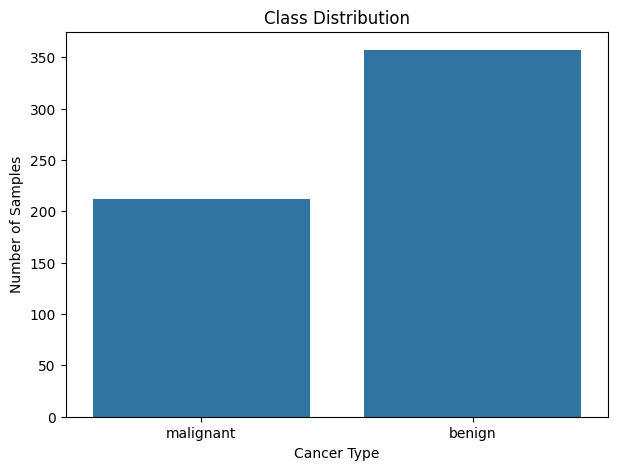

In [8]:
# Check missing values
missing = X.isnull().sum()
print('Total missing values:', int(missing.sum()))

# Class distribution
plt.figure(figsize=(7, 5))
sns.countplot(x=y.map({0: 'malignant', 1: 'benign'}))
plt.title('Class Distribution')
plt.xlabel('Cancer Type')
plt.ylabel('Number of Samples')
plt.show()

In [9]:
# Split data into training and unseen test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training samples:', len(X_train))
print('Testing samples :', len(X_test))

Training samples: 455
Testing samples : 114


## 2. Feature Selection

We use **SelectKBest with the ANOVA F-test** to identify the most informative features. Feature selection is performed inside the machine-learning pipeline so that information from the test set does not leak into training.

Top 10 features:


,Feature,ANOVA F-Score
27,worst concave points,795.223341
22,worst perimeter,719.598823
7,mean concave points,703.364031
20,worst radius,687.430367
2,mean perimeter,565.485755
23,worst area,541.713694
0,mean radius,523.613907
3,mean area,469.516453
6,mean concavity,416.374874
26,worst concavity,365.747389


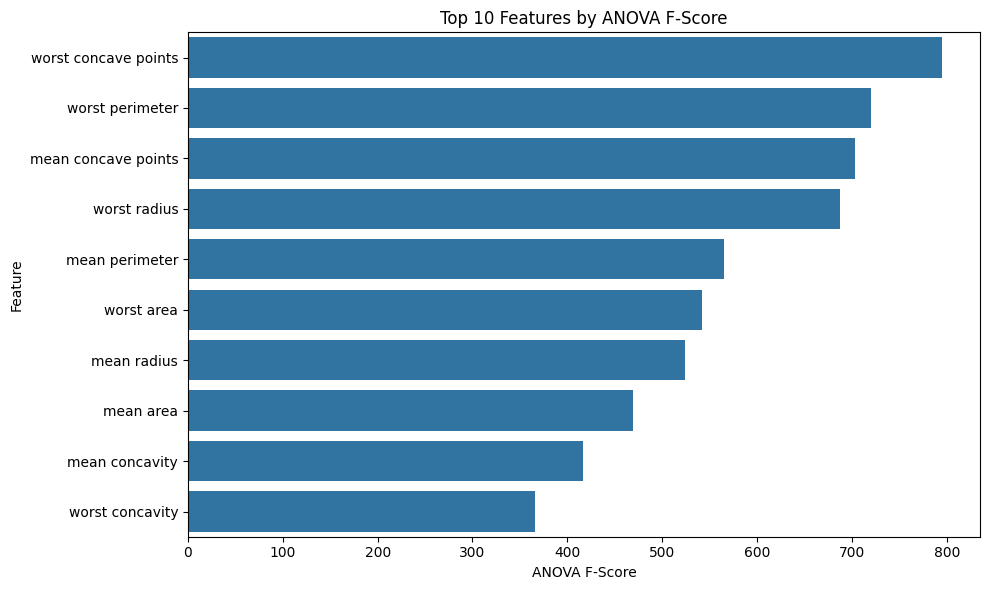

In [10]:
# Inspect the top features using the training set only
selector_preview = SelectKBest(score_func=f_classif, k=10)
selector_preview.fit(X_train, y_train)

feature_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'ANOVA F-Score': selector_preview.scores_
}).sort_values('ANOVA F-Score', ascending=False)

print('Top 10 features:')
display(feature_scores.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_scores.head(10), x='ANOVA F-Score', y='Feature')
plt.title('Top 10 Features by ANOVA F-Score')
plt.tight_layout()
plt.show()

## 3. Model Training

The complete pipeline is:

**Median imputation → Standardization → Feature selection → SVM classifier**

We then use `GridSearchCV` with stratified 5-fold cross-validation to tune the number of selected features and SVM hyperparameters.

In [11]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('feature_selection', SelectKBest(score_func=f_classif, k=10)),
    ('classifier', SVC(probability=True, random_state=42))
])

param_grid = {
    'feature_selection__k': [5, 10, 15, 20, 'all'],
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto'],
    'classifier__kernel': ['linear', 'rbf']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print('\nBest parameters:')
print(grid_search.best_params_)
print('\nBest cross-validation accuracy: {:.4f}'.format(grid_search.best_score_))

Fitting 5 folds for each of 80 candidates, totalling 400 fits

Best parameters:
{'classifier__C': 0.1, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear', 'feature_selection__k': 20}

Best cross-validation accuracy: 0.9802


## 4. Evaluation

The optimized model is evaluated on the **unseen test set** using accuracy, precision, recall, F1-score, ROC-AUC, a confusion matrix, and an ROC curve.

In [12]:
y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_probability)

metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Score': [accuracy, precision, recall, f1, auc]
})

display(metrics_df.style.format({'Score': '{:.4f}'}))

print('\nClassification Report:\n')
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

,Metric,Score
0,Accuracy,0.9825
1,Precision,0.9861
2,Recall,0.9861
3,F1 Score,0.9861
4,ROC-AUC,0.9937



Classification Report:

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



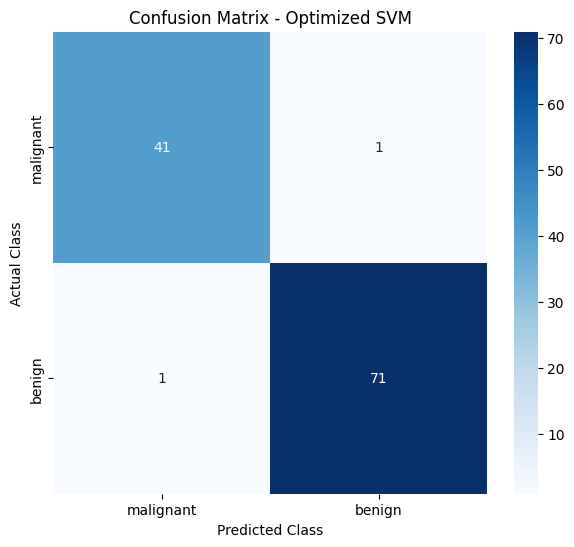

In [13]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.title('Confusion Matrix - Optimized SVM')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

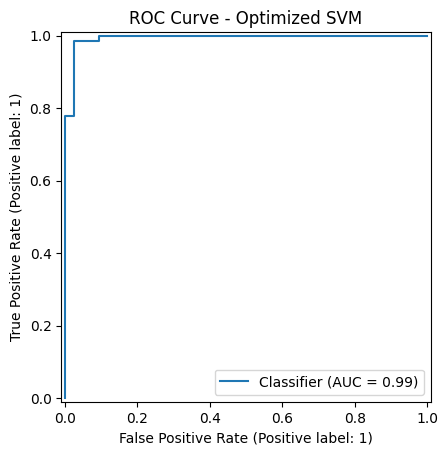

In [14]:
# ROC curve
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title('ROC Curve - Optimized SVM')
plt.show()

## Actual vs Predicted Results

In [15]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Prediction Probability': y_probability
})

results['Actual'] = results['Actual'].map({0: 'malignant', 1: 'benign'})
results['Predicted'] = results['Predicted'].map({0: 'malignant', 1: 'benign'})

display(results.head(20))

,Actual,Predicted,Prediction Probability
0,malignant,malignant,5.566555e-07
1,benign,benign,1.000000e+00
2,malignant,malignant,7.001896e-03
3,benign,benign,4.673410e-01
4,malignant,malignant,1.000000e-07
5,benign,benign,9.886944e-01
6,benign,benign,1.000000e+00
7,malignant,malignant,1.786145e-06
8,malignant,malignant,2.615159e-04
9,malignant,malignant,1.000000e-07


## Pipeline Summary

| Step | Implementation |
|---|---|
| **1. Data Prep** | Load dataset, check missing values, split data, impute and standardize |
| **2. Feature Selection** | SelectKBest + ANOVA F-test |
| **3. Model Training** | SVM classifier + GridSearchCV hyperparameter tuning |
| **4. Evaluation** | Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrix and ROC curve |

In [16]:
# Save the complete trained pipeline for later use
import joblib

joblib.dump(best_model, 'breast_cancer_svm_pipeline.pkl')
print('Saved: breast_cancer_svm_pipeline.pkl')

Saved: breast_cancer_svm_pipeline.pkl


## Test a New Sample

The following uses one unseen test sample to demonstrate a final prediction.

In [17]:
sample = X_test.iloc[[0]]
prediction = best_model.predict(sample)[0]
probability = best_model.predict_proba(sample)[0]

print('Predicted class:', data.target_names[prediction])
print('Malignant probability: {:.2%}'.format(probability[0]))
print('Benign probability   : {:.2%}'.format(probability[1]))

Predicted class: malignant
Malignant probability: 100.00%
Benign probability   : 0.00%
